<a href="https://colab.research.google.com/github/VaishnaviMalaji/BIS-LAB/blob/main/BIS_LAB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Week - 1 GENETIC ALGORITHM

In [ ]:
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# 1. Load dataset
data = load_breast_cancer()
X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 2. Standardize using training data only
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 3. Define GA parameters
rng = np.random.default_rng(42)
n_features = X_train.shape[1]
population_size = 20
generations = 15
mutation_rate = 0.05

# Each chromosome is a binary feature-selection mask
population = rng.integers(
    0, 2, size=(population_size, n_features)
)
population[:, 0] = 1  # Ensure at least one feature is selected

def fitness(mask):
    selected = np.flatnonzero(mask)
    if len(selected) == 0:
        return 0.0

    model = KNeighborsClassifier(n_neighbors=5)
    model.fit(X_train[:, selected], y_train)
    predictions = model.predict(X_test[:, selected])

    accuracy = accuracy_score(y_test, predictions)
    penalty = 0.01 * len(selected) / n_features

    return accuracy - penalty

# 4. Evolve the population
for generation in range(generations):
    scores = np.array([fitness(ch) for ch in population])
    best_idx = np.argmax(scores)
    best = population[best_idx].copy()

    # Elitism: preserve best chromosome
    new_population = [best]

    while len(new_population) < population_size:
        # Tournament selection
        i, j = rng.integers(0, population_size, size=2)
        p1 = population[i] if scores[i] > scores[j] else population[j]

        i, j = rng.integers(0, population_size, size=2)
        p2 = population[i] if scores[i] > scores[j] else population[j]

        # Single-point crossover
        point = rng.integers(1, n_features)
        child = np.concatenate([p1[:point], p2[point:]])

        # Bit-flip mutation
        flips = rng.random(n_features) < mutation_rate
        child[flips] = 1 - child[flips]

        if child.sum() == 0:
            child[rng.integers(n_features)] = 1

        new_population.append(child)

    population = np.array(new_population)

# 5. Evaluate the best selected subset
scores = np.array([fitness(ch) for ch in population])
best_mask = population[np.argmax(scores)]
selected = np.flatnonzero(best_mask)

final_model = KNeighborsClassifier(n_neighbors=5)
final_model.fit(X_train[:, selected], y_train)
predictions = final_model.predict(X_test[:, selected])

print("Total features:", n_features)
print("Selected features:", len(selected))
print("Selected feature names:",
      list(data.feature_names[selected]))
print("Test accuracy:", round(
    accuracy_score(y_test, predictions), 4
))

Total features: 30
Selected features: 15
Selected feature names: [np.str_('mean texture'), np.str_('mean smoothness'), np.str_('mean compactness'), np.str_('mean concave points'), np.str_('mean fractal dimension'), np.str_('radius error'), np.str_('texture error'), np.str_('smoothness error'), np.str_('concavity error'), np.str_('fractal dimension error'), np.str_('worst radius'), np.str_('worst texture'), np.str_('worst area'), np.str_('worst concavity'), np.str_('worst concave points')]
Test accuracy: 0.9825


WEEK - 2 Particle Swarm

In [ ]:
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Load dataset
data = load_breast_cancer()
X, y = data.data, data.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

n_features = X.shape[1]
n_particles = 10
iterations = 15

# Initialize particles and velocities
particles = np.random.randint(0, 2, (n_particles, n_features))
velocities = np.random.uniform(-1, 1, (n_particles, n_features))

pbest = particles.copy()
pbest_score = np.zeros(n_particles)
gbest = particles[0].copy()
gbest_score = 0

# PSO loop
for _ in range(iterations):
    for i in range(n_particles):

        features = np.where(particles[i] == 1)[0]

        if len(features) == 0:
            continue

        # Evaluate particle
        model = RandomForestClassifier(n_estimators=50, random_state=42)
        model.fit(X_train[:, features], y_train)
        accuracy = accuracy_score(
            y_test, model.predict(X_test[:, features])
        )

        # Fitness = accuracy - small feature penalty
        fitness = accuracy - 0.01 * len(features) / n_features

        # Update personal best
        if fitness > pbest_score[i]:
            pbest_score[i] = fitness
            pbest[i] = particles[i].copy()

        # Update global best
        if fitness > gbest_score:
            gbest_score = fitness
            gbest = particles[i].copy()

    # Update particles
    for i in range(n_particles):
        r1, r2 = np.random.rand(n_features), np.random.rand(n_features)

        velocities[i] = (
            0.7 * velocities[i]
            + 1.5 * r1 * (pbest[i] - particles[i])
            + 1.5 * r2 * (gbest - particles[i])
        )

        prob = 1 / (1 + np.exp(-velocities[i]))
        particles[i] = (np.random.rand(n_features) < prob).astype(int)

# Final model
features = np.where(gbest == 1)[0]

model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train[:, features], y_train)
accuracy = accuracy_score(y_test, model.predict(X_test[:, features]))

print("Original features:", n_features)
print("Selected features:", len(features))
print("Selected feature indexes:", features)
print("Final accuracy:", round(accuracy * 100, 2), "%")

Original features: 30
Selected features: 12
Selected feature indexes: [ 1  6 11 12 13 15 17 21 22 24 26 28]
Final accuracy: 99.12 %


Week - 3 Any colony Optimization

========== RESULTS ==========
ACO best distance: 410.60
Nearest-neighbor distance: 502.69
ACO execution time: 8.317 seconds
Nearest-neighbor execution time: 0.002 seconds
ACO improvement over NN: 18.32%


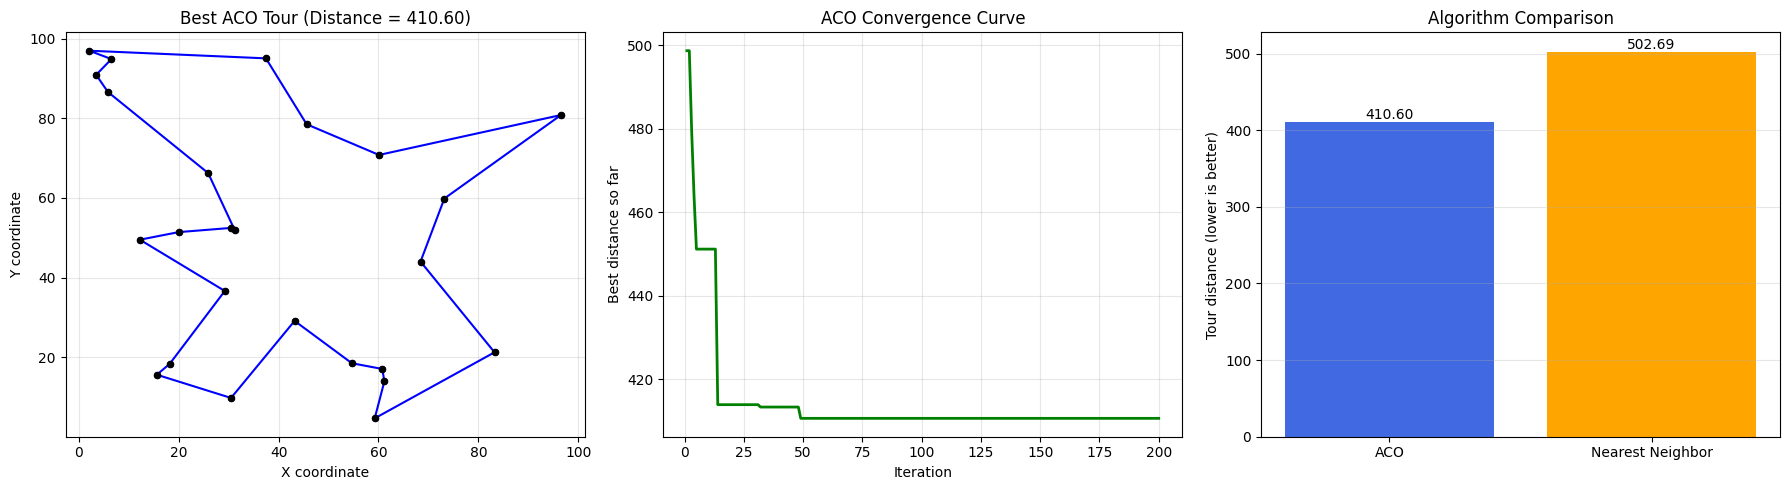

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import time

# ==========================================
# 1. CREATE THE TSP CITY DATA
# ==========================================
np.random.seed(42)

N_CITIES = 25
cities = np.random.rand(N_CITIES, 2) * 100

# Calculate distances between every pair of cities
diff = cities[:, np.newaxis, :] - cities[np.newaxis, :, :]
distance = np.sqrt(np.sum(diff**2, axis=2))
np.fill_diagonal(distance, np.inf)


def tour_length(tour):
    """Calculate total distance, including return to start."""
    return sum(
        distance[tour[i], tour[(i + 1) % len(tour)]]
        for i in range(len(tour))
    )


# ==========================================
# 2. NEAREST-NEIGHBOR ALGORITHM
# ==========================================
def nearest_neighbor(start):
    unvisited = set(range(N_CITIES))
    unvisited.remove(start)
    tour = [start]

    while unvisited:
        current = tour[-1]
        next_city = min(
            unvisited,
            key=lambda city: distance[current, city]
        )
        tour.append(next_city)
        unvisited.remove(next_city)

    return tour


# Try every starting city for a stronger baseline
nn_start = time.perf_counter()
nn_tours = [nearest_neighbor(i) for i in range(N_CITIES)]
nn_best_tour = min(nn_tours, key=tour_length)
nn_best_distance = tour_length(nn_best_tour)
nn_time = time.perf_counter() - nn_start


# ==========================================
# 3. ANT COLONY OPTIMIZATION
# ==========================================
def ant_colony_optimization(
    n_ants=25,
    n_iterations=200,
    alpha=1.0,
    beta=3.0,
    evaporation=0.5,
    Q=100
):
    pheromone = np.ones((N_CITIES, N_CITIES))
    heuristic = 1.0 / (distance + 1e-10)

    best_tour = None
    best_distance = float("inf")
    history = []

    for iteration in range(n_iterations):
        all_tours = []
        all_lengths = []

        for ant in range(n_ants):
            start = np.random.randint(N_CITIES)
            tour = [start]
            unvisited = set(range(N_CITIES))
            unvisited.remove(start)

            while unvisited:
                current = tour[-1]
                candidates = np.array(sorted(unvisited))

                # Transition probabilities
                weights = (
                    pheromone[current, candidates] ** alpha
                    * heuristic[current, candidates] ** beta
                )
                probabilities = weights / weights.sum()

                next_city = np.random.choice(
                    candidates, p=probabilities
                )

                tour.append(int(next_city))
                unvisited.remove(int(next_city))

            length = tour_length(tour)
            all_tours.append(tour)
            all_lengths.append(length)

            if length < best_distance:
                best_distance = length
                best_tour = tour.copy()

        # Evaporate pheromone
        pheromone *= (1 - evaporation)

        # Deposit pheromone along each ant's tour
        for tour, length in zip(all_tours, all_lengths):
            deposit = Q / length

            for i in range(N_CITIES):
                a = tour[i]
                b = tour[(i + 1) % N_CITIES]
                pheromone[a, b] += deposit
                pheromone[b, a] += deposit

        history.append(best_distance)

    return best_tour, best_distance, history


# ==========================================
# 4. RUN ACO AND MEASURE EXECUTION TIME
# ==========================================
np.random.seed(123)

start_time = time.perf_counter()

aco_tour, aco_distance, history = ant_colony_optimization(
    n_ants=25,
    n_iterations=200,
    alpha=1.0,
    beta=3.0,
    evaporation=0.5,
    Q=100
)

aco_time = time.perf_counter() - start_time

print("========== RESULTS ==========")
print(f"ACO best distance: {aco_distance:.2f}")
print(f"Nearest-neighbor distance: {nn_best_distance:.2f}")
print(f"ACO execution time: {aco_time:.3f} seconds")
print(f"Nearest-neighbor execution time: {nn_time:.3f} seconds")

improvement = (
    (nn_best_distance - aco_distance) / nn_best_distance
) * 100

print(f"ACO improvement over NN: {improvement:.2f}%")


# ==========================================
# 5. GRAPH 1: BEST ACO TOUR
# ==========================================
def plot_tour(ax, tour, title, color):
    route = tour + [tour[0]]
    route = np.array(route)

    ax.plot(
        cities[route, 0],
        cities[route, 1],
        color=color,
        linewidth=1.5,
        marker="o",
        markersize=4
    )

    ax.scatter(
        cities[:, 0], cities[:, 1],
        color="black", s=20, zorder=3
    )

    ax.set_title(title)
    ax.set_xlabel("X coordinate")
    ax.set_ylabel("Y coordinate")
    ax.grid(True, alpha=0.3)


# ==========================================
# 6. GRAPH 2: CONVERGENCE CURVE
# ==========================================
# ==========================================
# 7. GRAPH 3: DISTANCE COMPARISON
# ==========================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

plot_tour(
    axes[0],
    aco_tour,
    f"Best ACO Tour (Distance = {aco_distance:.2f})",
    "blue"
)

axes[1].plot(
    range(1, len(history) + 1),
    history,
    color="green",
    linewidth=2
)
axes[1].set_title("ACO Convergence Curve")
axes[1].set_xlabel("Iteration")
axes[1].set_ylabel("Best distance so far")
axes[1].grid(True, alpha=0.3)

methods = ["ACO", "Nearest Neighbor"]
distances = [aco_distance, nn_best_distance]

bars = axes[2].bar(
    methods, distances,
    color=["royalblue", "orange"]
)
axes[2].set_title("Algorithm Comparison")
axes[2].set_ylabel("Tour distance (lower is better)")
axes[2].grid(axis="y", alpha=0.3)

for bar, value in zip(bars, distances):
    axes[2].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.2f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig("aco_tsp_results.png", dpi=300, bbox_inches="tight")
plt.show()

WEEK - 04 CUCKOO SEARCH

Device: CPU


Saving Screenshot (1).png to Screenshot (1).png
Image loaded: Screenshot (1).png
Image dimensions: (1920, 1080)


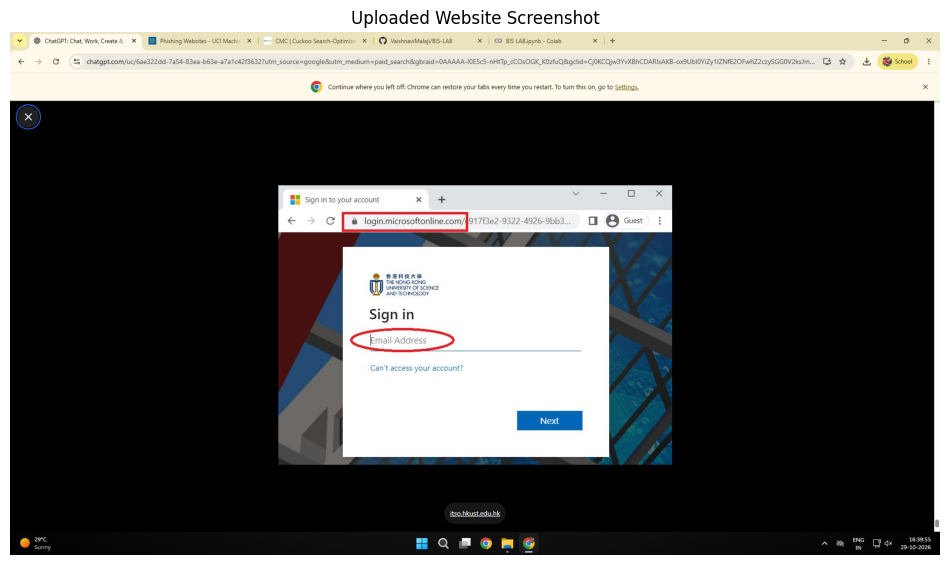

Loading pretrained CLIP model...


config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]


========== CLASSIFICATION RESULTS ==========
a screenshot of a phishing website designed to steal passwords or personal information using a fake login page: 0.4101
a screenshot of an ordinary informational website with no login or payment form: 0.2612
a screenshot of a suspicious website with deceptive branding, fake security warnings, or fraudulent payment requests: 0.1860
a screenshot of a legitimate and trustworthy website with an authentic login page: 0.1427

========== FINAL OUTPUT ==========
Predicted category: POTENTIALLY PHISHING
Best matching description: a screenshot of a phishing website designed to steal passwords or personal information using a fake login page

IMPORTANT: This is a zero-shot visual similarity result, not a validated phishing detector. The displayed scores are not calibrated phishing probabilities. Verify suspicious websites using their URL, domain reputation, and other security signals before deciding whether they are safe.


In [ ]:

# ============================================================
# SINGLE-IMAGE WEBSITE SCREENSHOT CLASSIFICATION
# Zero-shot Deep Learning using pretrained CLIP
# No external training dataset required
# Google Colab compatible
# ============================================================

%pip -q install transformers pillow torch

import torch
import matplotlib.pyplot as plt
from PIL import Image
from google.colab import files
from transformers import pipeline

# ------------------------------------------------------------
# 1. Select device
# ------------------------------------------------------------
device = 0 if torch.cuda.is_available() else -1
print("Device:", "GPU" if device == 0 else "CPU")

# ------------------------------------------------------------
# 2. Upload one website screenshot
# ------------------------------------------------------------
uploaded = files.upload()

if not uploaded:
    raise ValueError("Please upload a website screenshot.")

filename = next(iter(uploaded))

image = Image.open(filename).convert("RGB")

print("Image loaded:", filename)
print("Image dimensions:", image.size)

plt.figure(figsize=(12, 7))
plt.imshow(image)
plt.axis("off")
plt.title("Uploaded Website Screenshot")
plt.show()

# ------------------------------------------------------------
# 3. Load pretrained deep-learning model
# ------------------------------------------------------------
print("Loading pretrained CLIP model...")

classifier = pipeline(
    task="zero-shot-image-classification",
    model="openai/clip-vit-base-patch32",
    device=device
)

# ------------------------------------------------------------
# 4. Define candidate classes
# ------------------------------------------------------------
candidate_labels = [
    "a screenshot of a phishing website designed to steal passwords "
    "or personal information using a fake login page",

    "a screenshot of a legitimate and trustworthy website "
    "with an authentic login page",

    "a screenshot of a suspicious website with deceptive branding, "
    "fake security warnings, or fraudulent payment requests",

    "a screenshot of an ordinary informational website "
    "with no login or payment form"
]

# ------------------------------------------------------------
# 5. Perform zero-shot image classification
# ------------------------------------------------------------
results = classifier(
    image,
    candidate_labels=candidate_labels
)

print("\n========== CLASSIFICATION RESULTS ==========")

for item in results:
    print(f"{item['label']}: {item['score']:.4f}")

# ------------------------------------------------------------
# 6. Interpret the best-matching visual description
# ------------------------------------------------------------
best_label = results[0]["label"]

phishing_phrases = [
    "phishing website",
    "suspicious website"
]

if any(phrase in best_label.lower()
       for phrase in phishing_phrases):
    prediction = "POTENTIALLY PHISHING"
else:
    prediction = "VISUALLY MORE CONSISTENT WITH LEGITIMATE/INFORMATIONAL"

print("\n========== FINAL OUTPUT ==========")
print("Predicted category:", prediction)
print("Best matching description:", best_label)

print(
    "\nIMPORTANT: This is a zero-shot visual similarity result, "
    "not a validated phishing detector. The displayed scores are "
    "not calibrated phishing probabilities. Verify suspicious "
    "websites using their URL, domain reputation, and other security "
    "signals before deciding whether they are safe."
)


WEEK 5 - GREY WOLF OPTIMIZER

In [1]:

import random
import math

# Network settings
N = 30
AREA = 100
BS = (50, 50)
INITIAL_ENERGY = 1.0
ROUNDS = 50
NUM_WOLVES = 10
ITERATIONS = 30
NUM_CH = 4

# Create sensor nodes
nodes = []
for i in range(N):
    nodes.append({
        "id": i,
        "x": random.uniform(0, AREA),
        "y": random.uniform(0, AREA),
        "energy": INITIAL_ENERGY,
        "buffer": random.uniform(0.5, 1.0)
    })

def distance(a, b):
    return math.sqrt((a[0]-b[0])**2 + (a[1]-b[1])**2)

# Fitness of selected cluster heads
def fitness(solution):
    heads = [i for i in range(N) if solution[i] == 1]

    if len(heads) == 0:
        return 999999

    total = 0
    for i in range(N):
        node = nodes[i]
        if node["energy"] <= 0:
            continue

        pos = (node["x"], node["y"])

        if i in heads:
            d = distance(pos, BS)
            total += 0.5 * d / 141.42
            total += 0.5 * (1 - node["energy"])
        else:
            nearest = min(
                distance(pos, (nodes[h]["x"], nodes[h]["y"]))
                for h in heads
            )
            total += nearest / 141.42

    return total / N + abs(len(heads) - NUM_CH) * 0.1

# Grey Wolf Optimization
def gwo():
    wolves = [
        [random.randint(0, 1) for _ in range(N)]
        for _ in range(NUM_WOLVES)
    ]

    for t in range(ITERATIONS):
        wolves.sort(key=fitness)

        alpha = wolves[0][:]
        beta = wolves[1][:]
        delta = wolves[2][:]

        a = 2 - 2 * t / ITERATIONS

        new_wolves = [alpha[:]]

        for wolf in wolves[1:]:
            new = []

            for j in range(N):
                r = random.random()
                A = 2 * a * r - a

                if abs(A) < 1:
                    value = alpha[j]
                elif random.random() < 0.5:
                    value = beta[j]
                else:
                    value = delta[j]

                # Binary position update
                if random.random() < 0.7:
                    new.append(value)
                else:
                    new.append(random.randint(0, 1))

            new_wolves.append(new)

        wolves = new_wolves

    return min(wolves, key=fitness)

# Network simulation
alive_rounds = 0

for r in range(ROUNDS):
    if not any(n["energy"] > 0 for n in nodes):
        break

    best = gwo()
    heads = [i for i in range(N)
             if best[i] == 1 and nodes[i]["energy"] > 0]

    if not heads:
        heads = [max(range(N),
                     key=lambda i: nodes[i]["energy"])]

    for i, node in enumerate(nodes):
        if node["energy"] <= 0:
            continue

        pos = (node["x"], node["y"])

        if i in heads:
            cost = 0.002 + distance(pos, BS) * 0.00001
        else:
            nearest = min(
                distance(pos, (nodes[h]["x"], nodes[h]["y"]))
                for h in heads
            )
            cost = 0.001 + nearest * 0.00001

        node["energy"] = max(0, node["energy"] - cost)

    alive_rounds += 1

    print("Round:", r + 1,
          "| Cluster Heads:", heads,
          "| Alive Nodes:",
          sum(n["energy"] > 0 for n in nodes))

# Final results
remaining = sum(n["energy"] for n in nodes)
alive = sum(n["energy"] > 0 for n in nodes)

print("\n--- FINAL RESULTS ---")
print("Network Lifetime:", alive_rounds, "rounds")
print("Alive Nodes:", alive)
print("Dead Nodes:", N - alive)
print("Remaining Energy:", round(remaining, 4))


Round: 1 | Cluster Heads: [15, 24, 28, 29] | Alive Nodes: 30
Round: 2 | Cluster Heads: [5, 6, 15, 22] | Alive Nodes: 30
Round: 3 | Cluster Heads: [1, 5, 8, 23] | Alive Nodes: 30
Round: 4 | Cluster Heads: [9, 19, 23, 27] | Alive Nodes: 30
Round: 5 | Cluster Heads: [4, 11, 19, 29] | Alive Nodes: 30
Round: 6 | Cluster Heads: [3, 19, 20, 28] | Alive Nodes: 30
Round: 7 | Cluster Heads: [5, 15, 20, 21] | Alive Nodes: 30
Round: 8 | Cluster Heads: [5, 9, 14, 15] | Alive Nodes: 30
Round: 9 | Cluster Heads: [11, 13, 20, 28] | Alive Nodes: 30
Round: 10 | Cluster Heads: [5, 9, 11, 29] | Alive Nodes: 30
Round: 11 | Cluster Heads: [1, 4, 6, 25] | Alive Nodes: 30
Round: 12 | Cluster Heads: [17, 21, 23, 27] | Alive Nodes: 30
Round: 13 | Cluster Heads: [14, 15, 18, 19] | Alive Nodes: 30
Round: 14 | Cluster Heads: [7, 16, 25, 27] | Alive Nodes: 30
Round: 15 | Cluster Heads: [12, 14, 23, 24] | Alive Nodes: 30
Round: 16 | Cluster Heads: [5, 12, 15, 20] | Alive Nodes: 30
Round: 17 | Cluster Heads: [5, 8, 1

WEEK 6 - PARALLEL CELLULAR ALGORITHM

WEEK 7 - GENE EXPRESSION